# Pneumothorax Detection


## Installs & Imports

In [1]:
# Install Packages
# %pip install pydicom scikit-image scikit-learn xgboost imbalanced-learn tqdm -q

In [2]:
import os, glob, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from scipy import stats

# DICOM
from pydicom import dcmread

# Image processing
from skimage.transform import resize
from skimage.exposure import equalize_adapthist   # CLAHE
from skimage.feature  import hog, local_binary_pattern

# ML
from sklearn.pipeline        import Pipeline
from sklearn.preprocessing   import StandardScaler, LabelEncoder
from sklearn.decomposition   import PCA
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.linear_model    import LogisticRegression
from sklearn.svm             import SVC
from sklearn.ensemble        import RandomForestClassifier
from sklearn.neighbors       import KNeighborsClassifier
from sklearn.metrics         import (
    roc_auc_score, f1_score, accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
    classification_report
)

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print('XGBoost not found – will be skipped')

try:
    from imblearn.over_sampling import SMOTE
    HAS_SMOTE = True
except ImportError:
    HAS_SMOTE = False
    print('imbalanced-learn not found – SMOTE will be skipped')

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print('All imports OK')

All imports OK


## 1. Configuration
Adjust the paths

In [3]:
DATA_DIR  = 'data/dicom_files'  
RLE_CSV   = 'data/train-rle.csv'

# Preprocessing
TARGET_SIZE  = (128, 128)   # all images resized to this
APPLY_CLAHE  = True         # contrast-limited adaptive histogram equalisation

# Feature params
HOG_ORIENT      = 9
HOG_PIX_CELL    = (16, 16)
HOG_CELL_BLOCK  = (2, 2)
LBP_RADIUS      = 3
LBP_N_POINTS    = 8 * LBP_RADIUS
LBP_N_BINS      = 64

# Evaluation
N_FOLDS     = 5
TEST_SIZE   = 0.20
PCA_VAR     = 0.95          # variance to retain in PCA

print(f'Config OK | target: {TARGET_SIZE} | CLAHE: {APPLY_CLAHE}')

Config OK | target: (128, 128) | CLAHE: True


## 2. Helper Functions
### 2.1 RLE decoder

In [4]:
# Decodes Run-Length Encoded (RLE) pixel masks to numpy arrays
def rle2mask(rle_str, width=1024, height=1024):
    mask = np.zeros(width * height, dtype=np.uint8)
    rle_str = str(rle_str).strip()
    if '-1' in rle_str:
        return mask.reshape(width, height, order='F')
    
    arr = np.array(rle_str.split(), dtype=int)
    starts  = arr[0::2]
    lengths = arr[1::2]
    
    pos = 0
    for start, length in zip(starts, lengths):
        pos += start
        mask[pos : pos + length] = 255
        pos += length
    
    return mask.reshape(width, height, order='F')


def rle_pixel_count(rle_str):
    rle_str = str(rle_str).strip()
    if '-1' in rle_str:
        return 0
    arr = np.array(rle_str.split(), dtype=int)
    return int(arr[1::2].sum())

### 2.2 Image preprocessing

In [5]:
# Load Dicom, Normalizes, CLAHE(Contrast Limited Adaptive Histogram Equalization), Resize
def load_and_preprocess(dcm_path, target_size=TARGET_SIZE, clahe=APPLY_CLAHE):
    dcm  = dcmread(dcm_path)
    img  = dcm.pixel_array.astype(np.float32)
    
    # Normalise to [0, 1]
    img -= img.min()
    if img.max() > 0:
        img /= img.max()
    
    # CLAHE: works on float images in [0,1]
    if clahe:
        img = equalize_adapthist(img).astype(np.float32)
    
    # Resize
    img = resize(img, target_size, anti_aliasing=True).astype(np.float32)
    
    return img

### 2.3 Feature extraction

In [6]:
def extract_global_stats(img):
    # Statistics (mean, stf, min, max, p10, p25, p50, p75, p90, skewness)
    # To extart mean and the skewness of the distribution because when pneumothorax region is filled with the air it appears darker
    flat = img.ravel()
    return np.array([
        flat.mean(),
        flat.std(),
        flat.min(),
        flat.max(),
        np.percentile(flat, 10),
        np.percentile(flat, 25),
        np.percentile(flat, 50),
        np.percentile(flat, 75),
        np.percentile(flat, 90),
        stats.skew(flat)
    ], dtype=np.float32)


def extract_hog_features(img):
    # Pneumothorax creates a pleural boundary which is an edge between the air pocket and lung tissue, the HOG detects to detect such edges
    feat, _ = hog(
        img,
        orientations=HOG_ORIENT,
        pixels_per_cell=HOG_PIX_CELL,
        cells_per_block=HOG_CELL_BLOCK,
        visualize=True,
        channel_axis=None
    )
    return feat.astype(np.float32)


def extract_lbp_features(img):
    # Captures micro-textures/ An air-filled pneumothorax region has a very different, smoother texture — LBP captures that difference
    lbp  = local_binary_pattern(img, LBP_N_POINTS, LBP_RADIUS, method='uniform')
    hist, _ = np.histogram(lbp.ravel(), bins=LBP_N_BINS, range=(0, LBP_N_BINS), density=True)
    return hist.astype(np.float32)


def extract_region_stats(img):
    # Spatial asymmetry / One ide of lubg being significantly darker(strong diagnostic signal that global statistics would miss)
    h, w = img.shape
    quads = [
        img[:h//2, :w//2],   # top-left
        img[:h//2, w//2:],   # top-right
        img[h//2:, :w//2],   # bottom-left
        img[h//2:, w//2:]    # bottom-right
    ]
    feats = []
    for q in quads:
        feats.extend([q.mean(), q.std()])
    return np.array(feats, dtype=np.float32)


# Concatnation of all features
def extract_all_features(img):
    feats = np.concatenate([
        extract_global_stats(img),
        extract_hog_features(img),
        extract_lbp_features(img),
        extract_region_stats(img)
    ])
    return feats

print('Feature extractor functions defined')

Feature extractor functions defined


## 3. Build the Database

We read the CSV, deduplicate by `ImageId`, then loop through the DICOM files to enrich the table with Age, Sex, and computed PneumothArea (cm²). We handle cases where files are missing gracefully.

In [7]:
# Load CSV
raw_df = pd.read_csv(RLE_CSV)
print("raw file length", len(raw_df))
raw_df.columns = raw_df.columns.str.strip()
raw_df['ImageId'] = raw_df['ImageId'].str.strip()
raw_df['EncodedPixels'] = raw_df['EncodedPixels'].astype(str).str.strip()

# Deduplicate by ImageId keeping all RLE rows
# A patient is healthy only if ALL their RLE rows are '-1'
def aggregate_patient(group):
    all_neg = all(v == '-1' for v in group['EncodedPixels'])
    # total pixel count across all masks for this image
    n_pix = sum(rle_pixel_count(v) for v in group['EncodedPixels'])
    # keep the first non-(-1) RLE for mask reconstruction, else '-1'
    rle_for_mask = '-1'
    for v in group['EncodedPixels']:
        if v != '-1':
            rle_for_mask = v
            break
    return pd.Series({
        'Healthy'    : all_neg,
        'n_pix_total': n_pix,
        'rle_mask'   : rle_for_mask
    })

myDB = raw_df.groupby('ImageId').apply(aggregate_patient).reset_index()

# Add columns to be filled from DICOM headers
myDB['Age']          = np.nan
myDB['Sex']          = 'N/A'
myDB['PneumothArea'] = np.nan   # cm²
myDB['HasFile']      = False
myDB['PixelSpacing'] = np.nan

print(f'Total unique images in CSV : {len(myDB)}')
print(f'Healthy                    : {myDB["Healthy"].sum()}')
print(f'Pneumothorax               : {(~myDB["Healthy"]).sum()}')
myDB.head(10)

raw file length 11582
Total unique images in CSV : 10675
Healthy                    : 8296
Pneumothorax               : 2379


,ImageId,Healthy,n_pix_total,rle_mask,Age,Sex,PneumothArea,HasFile,PixelSpacing
0,1.2.276.0.7230010.3.1.4.8323329.1000.151787516...,True,0,-1,NaN,N/A,NaN,False,NaN
1,1.2.276.0.7230010.3.1.4.8323329.10000.15178752...,True,0,-1,NaN,N/A,NaN,False,NaN
2,1.2.276.0.7230010.3.1.4.8323329.10001.15178752...,True,0,-1,NaN,N/A,NaN,False,NaN
3,1.2.276.0.7230010.3.1.4.8323329.10002.15178752...,True,0,-1,NaN,N/A,NaN,False,NaN
4,1.2.276.0.7230010.3.1.4.8323329.10003.15178752...,True,0,-1,NaN,N/A,NaN,False,NaN
5,1.2.276.0.7230010.3.1.4.8323329.10004.15178752...,True,0,-1,NaN,N/A,NaN,False,NaN
6,1.2.276.0.7230010.3.1.4.8323329.10005.15178752...,False,6682,209126 1 1019 6 1015 10 1012 13 1010 14 1008 1...,NaN,N/A,NaN,False,NaN
7,1.2.276.0.7230010.3.1.4.8323329.10006.15178752...,True,0,-1,NaN,N/A,NaN,False,NaN
8,1.2.276.0.7230010.3.1.4.8323329.10007.15178752...,True,0,-1,NaN,N/A,NaN,False,NaN
9,1.2.276.0.7230010.3.1.4.8323329.10008.15178752...,True,0,-1,NaN,N/A,NaN,False,NaN


In [8]:
# Scan DICOM files and populate DB columns
dicom_files = glob.glob(os.path.join(DATA_DIR, '*.dcm'))
dicom_map   = {os.path.splitext(os.path.basename(f))[0]: f for f in dicom_files}

print(f'Found {len(dicom_files)} DICOM files in {DATA_DIR}')

for idx, row in tqdm(myDB.iterrows(), total=len(myDB), desc='Reading headers'):
    img_id = row['ImageId']
    if img_id not in dicom_map:
        continue
    try:
        dcm = dcmread(dicom_map[img_id])
        px_sp = float(dcm.PixelSpacing[0])  # mm/pixel (assume square)
        myDB.at[idx, 'Age']          = int(dcm.PatientAge) if dcm.PatientAge else np.nan
        myDB.at[idx, 'Sex']          = dcm.PatientSex
        myDB.at[idx, 'PixelSpacing'] = px_sp
        myDB.at[idx, 'HasFile']      = True
        # PneumothArea in cm² = n_pixels × (mm/pixel)² / 100
        myDB.at[idx, 'PneumothArea'] = row['n_pix_total'] * (px_sp ** 2) / 100.0
    except Exception as e:
        pass  # skip malformed files

# Keep only patients for which we have a DICOM file
myDB_valid = myDB[myDB['HasFile']].copy().reset_index(drop=True)
print(f'\nImages with DICOM file available: {len(myDB_valid)}')
print(myDB_valid[['ImageId','Healthy','Age','Sex','PneumothArea']].head(10))

Found 10719 DICOM files in data/dicom_files


Reading headers:   0%|          | 0/10675 [00:00<?, ?it/s]


Images with DICOM file available: 10675
                                             ImageId  Healthy   Age Sex  \
0  1.2.276.0.7230010.3.1.4.8323329.1000.151787516...     True  38.0   M   
1  1.2.276.0.7230010.3.1.4.8323329.10000.15178752...     True  10.0   F   
2  1.2.276.0.7230010.3.1.4.8323329.10001.15178752...     True  50.0   F   
3  1.2.276.0.7230010.3.1.4.8323329.10002.15178752...     True  68.0   F   
4  1.2.276.0.7230010.3.1.4.8323329.10003.15178752...     True  65.0   M   
5  1.2.276.0.7230010.3.1.4.8323329.10004.15178752...     True  45.0   F   
6  1.2.276.0.7230010.3.1.4.8323329.10005.15178752...    False  53.0   F   
7  1.2.276.0.7230010.3.1.4.8323329.10006.15178752...     True  55.0   M   
8  1.2.276.0.7230010.3.1.4.8323329.10007.15178752...     True  26.0   F   
9  1.2.276.0.7230010.3.1.4.8323329.10008.15178752...     True  63.0   M   

   PneumothArea  
0      0.000000  
1      0.000000  
2      0.000000  
3      0.000000  
4      0.000000  
5      0.000000  
6      

## 4. Exploratory Data Analysis

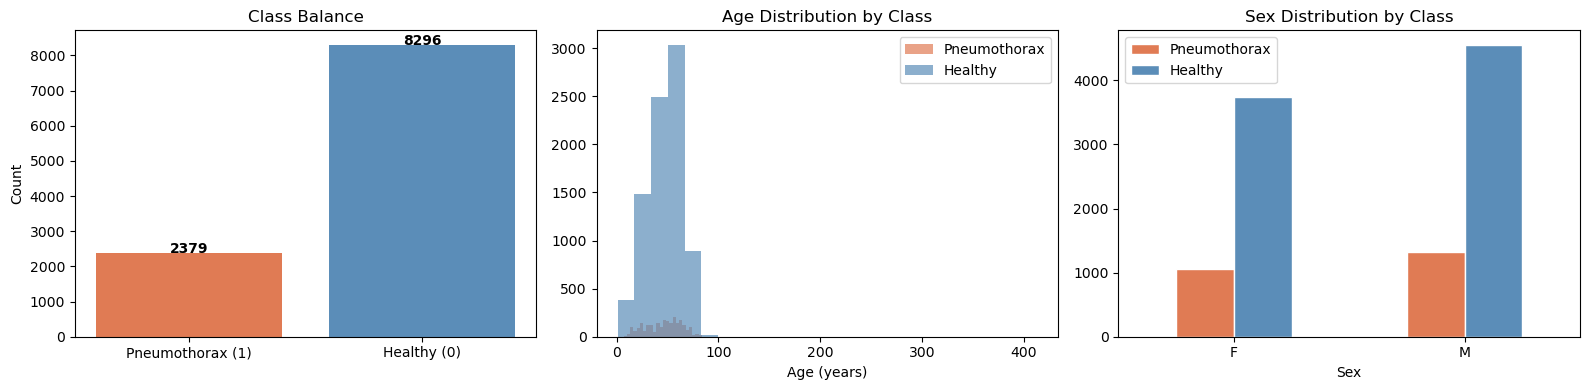

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Class balance
counts = myDB_valid['Healthy'].value_counts()
axes[0].bar(['Pneumothorax (1)', 'Healthy (0)'],
            [counts.get(False,0), counts.get(True,0)],
            color=['#e07b54', '#5b8db8'])
axes[0].set_title('Class Balance')
axes[0].set_ylabel('Count')
for i, v in enumerate([counts.get(False,0), counts.get(True,0)]):
    axes[0].text(i, v + 10, str(v), ha='center', fontweight='bold')

# Age distribution
axes[1].hist(myDB_valid[myDB_valid['Healthy']==False]['Age'].dropna(),
             bins=25, alpha=0.7, label='Pneumothorax', color='#e07b54')
axes[1].hist(myDB_valid[myDB_valid['Healthy']==True]['Age'].dropna(),
             bins=25, alpha=0.7, label='Healthy', color='#5b8db8')
axes[1].set_title('Age Distribution by Class')
axes[1].set_xlabel('Age (years)')
axes[1].legend()

# Sex distribution
sex_counts = myDB_valid.groupby(['Sex','Healthy']).size().unstack(fill_value=0)
sex_counts.plot(kind='bar', ax=axes[2], color=['#e07b54','#5b8db8'],
                rot=0, edgecolor='white')
axes[2].set_title('Sex Distribution by Class')
axes[2].set_xlabel('Sex')
axes[2].legend(['Pneumothorax','Healthy'])

plt.tight_layout()
plt.savefig('eda_overview.png', dpi=150, bbox_inches='tight')
plt.show()

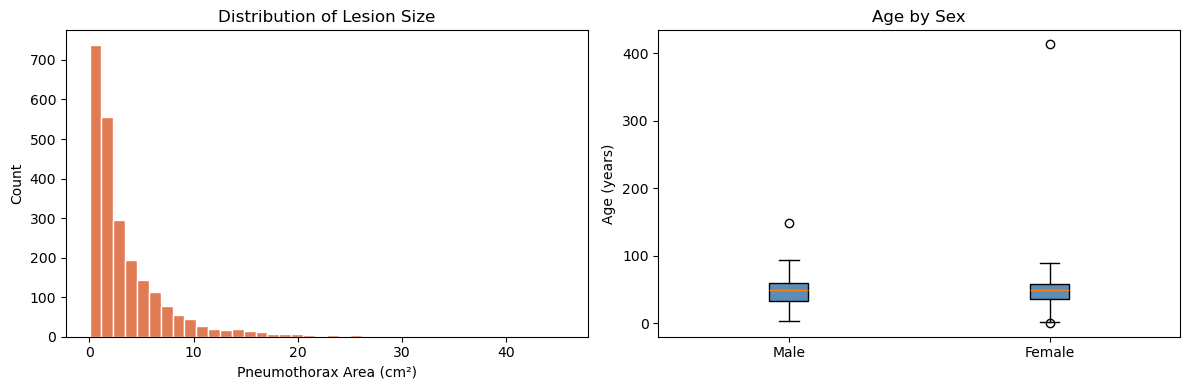

            Age  PneumothArea
count  10675.00      10675.00
mean      47.08          0.81
std       17.12          2.65
min        1.00          0.00
25%       35.00          0.00
50%       49.00          0.00
75%       60.00          0.00
max      413.00         45.56


In [10]:
# Pneumothorax area distribution (sick patients only)
sick = myDB_valid[~myDB_valid['Healthy'] & myDB_valid['PneumothArea'].notna()]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(sick['PneumothArea'], bins=40, color='#e07b54', edgecolor='white')
axes[0].set_xlabel('Pneumothorax Area (cm²)')
axes[0].set_title('Distribution of Lesion Size')
axes[0].set_ylabel('Count')

axes[1].boxplot(
    [myDB_valid[myDB_valid['Sex']=='M']['Age'].dropna(),
     myDB_valid[myDB_valid['Sex']=='F']['Age'].dropna()],
    labels=['Male','Female'],
    patch_artist=True,
    boxprops=dict(facecolor='#5b8db8')
)
axes[1].set_title('Age by Sex')
axes[1].set_ylabel('Age (years)')
plt.tight_layout()
plt.show()

print(myDB_valid[['Age','PneumothArea']].describe().round(2))

## 5. Mask Visualisation

Show the RLE mask overlaid on the original X-ray for a few positive cases — a key sanity check before modelling.

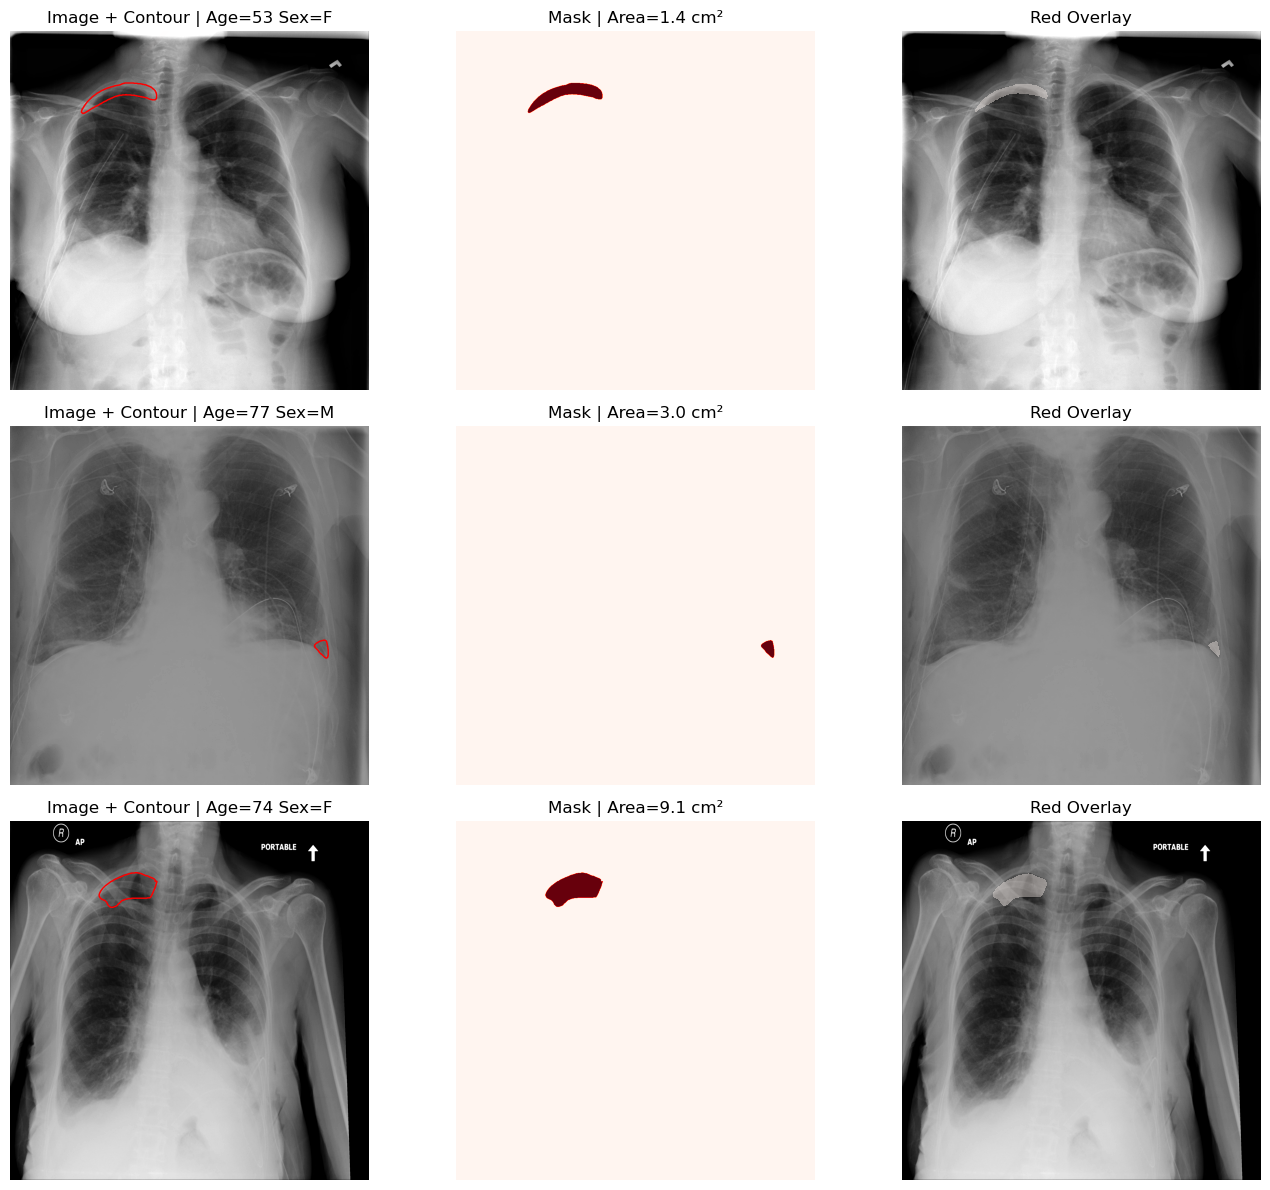

In [11]:
import os, glob

dicom_map = {os.path.splitext(os.path.basename(f))[0]: f
             for f in glob.glob(os.path.join(DATA_DIR, '*.dcm'))}

sick_cases = myDB_valid[~myDB_valid['Healthy'] & myDB_valid['HasFile']].head(3)

fig, axes = plt.subplots(len(sick_cases), 3, figsize=(14, 4 * len(sick_cases)))
if len(sick_cases) == 1:
    axes = axes[np.newaxis, :]

for row_i, (_, row) in enumerate(sick_cases.iterrows()):
    dcm  = dcmread(dicom_map[row['ImageId']])
    imm  = dcm.pixel_array.astype(float)
    mask = rle2mask(row['rle_mask'], width=1024, height=1024)
    
    # Panel 1 – image + mask contour
    axes[row_i, 0].imshow(imm, cmap='gray', vmin=10, vmax=240)
    axes[row_i, 0].contour(mask, [0.5], colors='red', linewidths=1)
    axes[row_i, 0].set_title(f'Image + Contour | Age={int(row["Age"])} Sex={row["Sex"]}')
    axes[row_i, 0].axis('off')
    
    # Panel 2 – mask alone
    axes[row_i, 1].imshow(mask, cmap='Reds')
    axes[row_i, 1].set_title(f'Mask | Area={row["PneumothArea"]:.1f} cm²')
    axes[row_i, 1].axis('off')
    
    # Panel 3 – red overlay
    axes[row_i, 2].imshow(imm, cmap='gray', vmin=10, vmax=240)
    overlay = mask.astype(float)
    overlay[overlay < 0.5] = np.nan
    axes[row_i, 2].imshow(overlay, cmap='Reds', alpha=0.4)
    axes[row_i, 2].set_title('Red Overlay')
    axes[row_i, 2].axis('off')

plt.tight_layout()
plt.savefig('mask_visualisation.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Load & Preprocess Images + Extract Features

We iterate over every patient with a DICOM file and compute:
- `X_stats` — global intensity stats (10-dim)
- `X_hog`   — HOG features (captures edge structure)
- `X_lbp`   — LBP histogram (texture)
- `X_reg`   — quadrant statistics (spatial asymmetry)
- `X_all`   — all concatenated

Labels:
- `y_pneu` — 1 = pneumothorax, 0 = healthy
- `y_sex`  — 1 = Female, 0 = Male

In [12]:
X_all_list  = []
y_pneu_list = []
y_sex_list  = []
valid_ids   = []

# For patients with no sex annotation we skip them for the sex task but keep them for pneumothorax task
for _, row in tqdm(myDB_valid.iterrows(), total=len(myDB_valid), desc='Loading images'):
    img_id = row['ImageId']
    if img_id not in dicom_map:
        continue
    try:
        img  = load_and_preprocess(dicom_map[img_id])
        feat = extract_all_features(img)
        
        X_all_list.append(feat)
        y_pneu_list.append(0 if row['Healthy'] else 1)
        
        sex = row['Sex']
        if sex == 'F':
            y_sex_list.append(1)
        elif sex == 'M':
            y_sex_list.append(0)
        else:
            y_sex_list.append(-1)  # unknown → will be filtered below
        
        valid_ids.append(img_id)
    except Exception as e:
        pass

X_all  = np.array(X_all_list,  dtype=np.float32)
y_pneu = np.array(y_pneu_list, dtype=int)
y_sex  = np.array(y_sex_list,  dtype=int)

# Filter out unknown sex
sex_mask = y_sex != -1

print(f'\nFeature matrix shape : {X_all.shape}')
print(f'Pneumothorax labels  : {y_pneu.sum()} positive / {(y_pneu==0).sum()} negative')
print(f'Sex labels (valid)   : {sex_mask.sum()} — F={( y_sex[sex_mask]==1).sum()}, M={(y_sex[sex_mask]==0).sum()}')

Loading images:   0%|          | 0/10675 [00:00<?, ?it/s]


Feature matrix shape : (10675, 1846)
Pneumothorax labels  : 2379 positive / 8296 negative
Sex labels (valid)   : 10675 — F=4795, M=5880


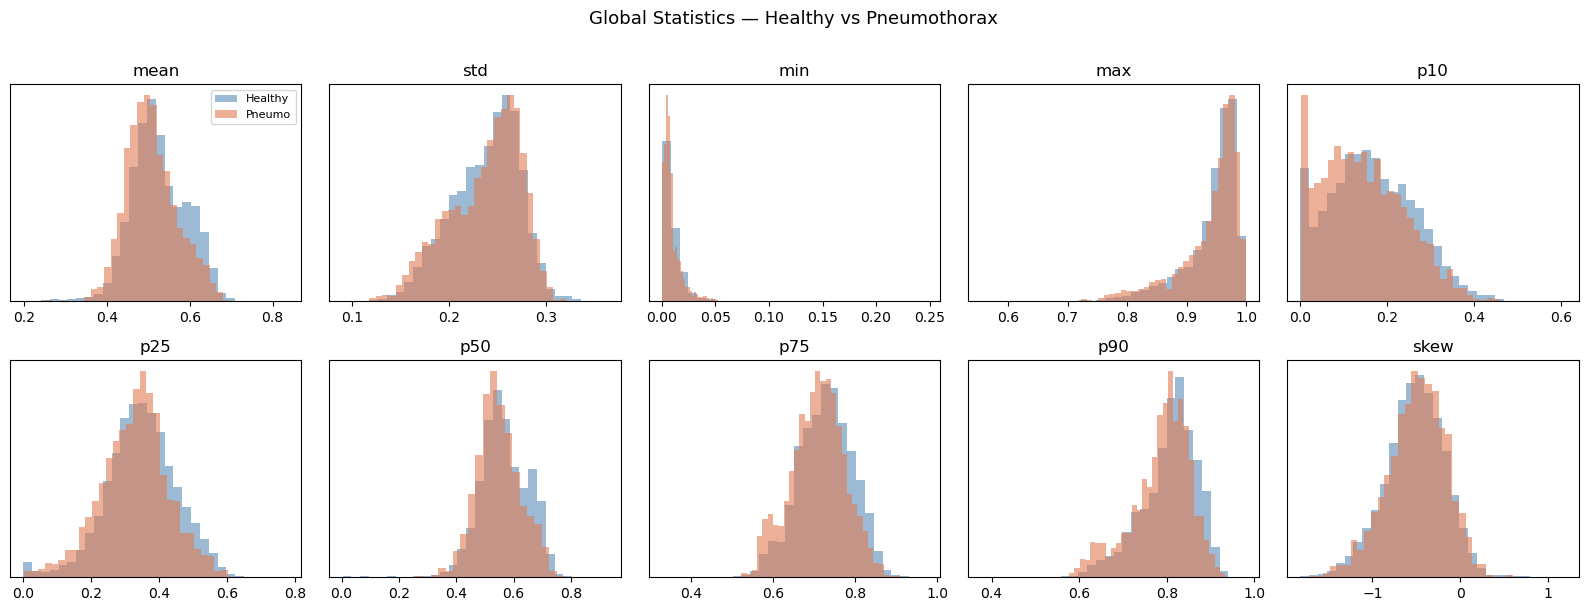

In [13]:
# Visualise feature distributions (first 10 = global stats)
feat_names = ['mean','std','min','max','p10','p25','p50','p75','p90','skew']

fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for i, ax in enumerate(axes.flat):
    ax.hist(X_all[y_pneu==0, i], bins=30, alpha=0.6, label='Healthy', color='#5b8db8', density=True)
    ax.hist(X_all[y_pneu==1, i], bins=30, alpha=0.6, label='Pneumo',  color='#e07b54', density=True)
    ax.set_title(feat_names[i])
    ax.set_yticks([])
    if i == 0:
        ax.legend(fontsize=8)
plt.suptitle('Global Statistics — Healthy vs Pneumothorax', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('feature_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Model Training & Evaluation

### 7.1 Evaluation utilities

In [14]:
def evaluate_cv(model, X, y, n_folds=N_FOLDS, label=''):
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=RANDOM_STATE)
    
    aucs, f1s, accs, sens, specs = [], [], [], [], []
    
    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
        X_tr, X_val = X[train_idx], X[val_idx]
        y_tr, y_val = y[train_idx], y[val_idx]
        
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        
        # Probability for AUC (falls back to decision_function)
        if hasattr(model, 'predict_proba'):
            y_prob = model.predict_proba(X_val)[:, 1]
        elif hasattr(model, 'decision_function'):
            y_prob = model.decision_function(X_val)
        else:
            y_prob = y_pred
        
        cm = confusion_matrix(y_val, y_pred)
        if cm.shape == (2,2):
            tn, fp, fn, tp = cm.ravel()
            sensitivity  = tp / (tp + fn + 1e-9)
            specificity  = tn / (tn + fp + 1e-9)
        else:
            sensitivity = specificity = np.nan
        
        aucs.append(roc_auc_score(y_val, y_prob))
        f1s.append(f1_score(y_val, y_pred, average='macro', zero_division=0))
        accs.append(accuracy_score(y_val, y_pred))
        sens.append(sensitivity)
        specs.append(specificity)
    
    results = {
        'Model'      : label,
        'AUC'        : f'{np.mean(aucs):.3f} ± {np.std(aucs):.3f}',
        'F1 (macro)' : f'{np.mean(f1s):.3f} ± {np.std(f1s):.3f}',
        'Accuracy'   : f'{np.mean(accs):.3f} ± {np.std(accs):.3f}',
        'Sensitivity': f'{np.mean(sens):.3f} ± {np.std(sens):.3f}',
        'Specificity': f'{np.mean(specs):.3f} ± {np.std(specs):.3f}',
        # Raw arrays for plotting
        '_auc_raw'   : aucs
    }
    return results


print('evaluate_cv() defined')

evaluate_cv() defined


### 7.2 Build model zoo

Each model is wrapped in a `Pipeline` with:
1. `StandardScaler` — zero-mean / unit-variance (critical for LR, SVM, k-NN)
2. `PCA` — dimensionality reduction to keep 95% of variance (stabilises SVM/k-NN on high-dim features)
3. Classifier with `class_weight='balanced'` where possible — compensates for class imbalance

In [15]:
def make_pipeline(clf):
    return Pipeline([
        ('scaler', StandardScaler()),
        ('pca',    PCA(n_components=PCA_VAR, random_state=RANDOM_STATE)),
        ('clf',    clf)
    ])


models = {
    'Logistic Regression': make_pipeline(
        LogisticRegression(max_iter=1000, class_weight='balanced',
                           random_state=RANDOM_STATE, solver='lbfgs')
    ),
    'SVM (RBF)': make_pipeline(
        SVC(kernel='rbf', class_weight='balanced', probability=True,
            random_state=RANDOM_STATE, C=1.0)
    ),
    'Random Forest': make_pipeline(
        RandomForestClassifier(n_estimators=200, class_weight='balanced',
                               random_state=RANDOM_STATE, n_jobs=-1)
    ),
    'k-NN': make_pipeline(
        KNeighborsClassifier(n_neighbors=7, weights='distance', n_jobs=-1)
    ),
}

if HAS_XGB:
    # XGBoost handles scale_pos_weight for imbalance
    n_neg = (y_pneu == 0).sum()
    n_pos = (y_pneu == 1).sum()
    models['XGBoost'] = make_pipeline(
        XGBClassifier(
            n_estimators=200, learning_rate=0.05,
            scale_pos_weight=n_neg / n_pos,
            random_state=RANDOM_STATE, use_label_encoder=False,
            eval_metric='logloss', n_jobs=-1
        )
    )

print(f'Model zoo: {list(models.keys())}')

Model zoo: ['Logistic Regression', 'SVM (RBF)', 'Random Forest', 'k-NN', 'XGBoost']


### 7.3 Task A — Pneumothorax Classification

In [16]:
print('=== TASK A: Pneumothorax Classification ===')
print(f'Classes: 0=Healthy ({(y_pneu==0).sum()}), 1=Pneumothorax ({(y_pneu==1).sum()})\n')

results_A = []
for name, pipe in models.items():
    print(f'  Training {name}...', end=' ')
    res = evaluate_cv(pipe, X_all, y_pneu, label=name)
    results_A.append(res)
    print(f"AUC={res['AUC']}  F1={res['F1 (macro)']}")

# Print summary table
summary_A = pd.DataFrame(results_A).set_index('Model')
summary_A_display = summary_A.drop(columns=['_auc_raw'])
print('\n── Task A Results ──')
print(summary_A_display.to_string())

=== TASK A: Pneumothorax Classification ===
Classes: 0=Healthy (8296), 1=Pneumothorax (2379)

  Training Logistic Regression... AUC=0.775 ± 0.009  F1=0.658 ± 0.009
  Training SVM (RBF)... AUC=0.831 ± 0.008  F1=0.723 ± 0.006
  Training Random Forest... AUC=0.738 ± 0.013  F1=0.438 ± 0.001
  Training k-NN... AUC=0.775 ± 0.009  F1=0.643 ± 0.016
  Training XGBoost... AUC=0.775 ± 0.008  F1=0.669 ± 0.007

── Task A Results ──
                               AUC     F1 (macro)       Accuracy    Sensitivity    Specificity
Model                                                                                         
Logistic Regression  0.775 ± 0.009  0.658 ± 0.009  0.716 ± 0.010  0.685 ± 0.014  0.724 ± 0.014
SVM (RBF)            0.831 ± 0.008  0.723 ± 0.006  0.790 ± 0.005  0.671 ± 0.010  0.824 ± 0.006
Random Forest        0.738 ± 0.013  0.438 ± 0.001  0.777 ± 0.000  0.001 ± 0.001  1.000 ± 0.000
k-NN                 0.775 ± 0.009  0.643 ± 0.016  0.797 ± 0.007  0.316 ± 0.025  0.934 ± 0.004
XGBoost

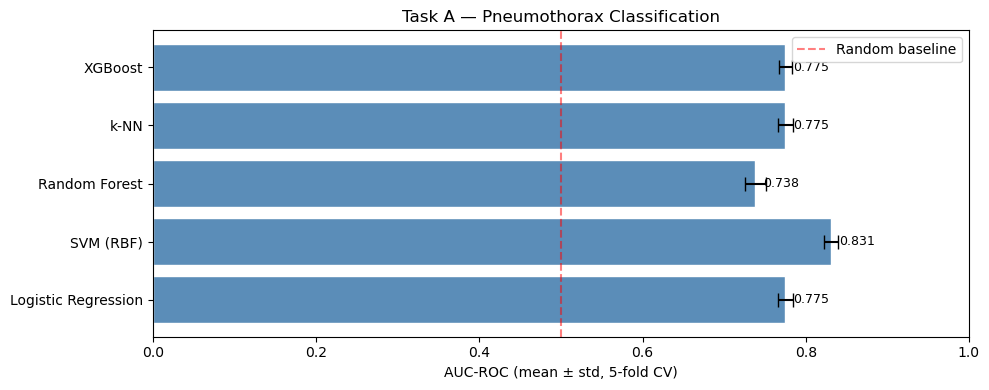

In [17]:
# Bar chart — AUC per model
model_names = [r['Model'] for r in results_A]
auc_means   = [float(r['AUC'].split(' ± ')[0]) for r in results_A]
auc_stds    = [float(r['AUC'].split(' ± ')[1]) for r in results_A]

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(model_names, auc_means, xerr=auc_stds,
               color='#5b8db8', edgecolor='white', capsize=5)
ax.set_xlabel('AUC-ROC (mean ± std, 5-fold CV)')
ax.set_title('Task A — Pneumothorax Classification')
ax.axvline(0.5, color='red', linestyle='--', alpha=0.5, label='Random baseline')
ax.legend()
ax.set_xlim(0, 1)
for bar, val in zip(bars, auc_means):
    ax.text(val + 0.01, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('task_A_auc.png', dpi=150, bbox_inches='tight')
plt.show()

Best model: SVM (RBF)

── Classification Report (test set) ──
              precision    recall  f1-score   support

     Healthy       0.89      0.83      0.86      1659
Pneumothorax       0.52      0.66      0.58       476

    accuracy                           0.79      2135
   macro avg       0.71      0.74      0.72      2135
weighted avg       0.81      0.79      0.80      2135



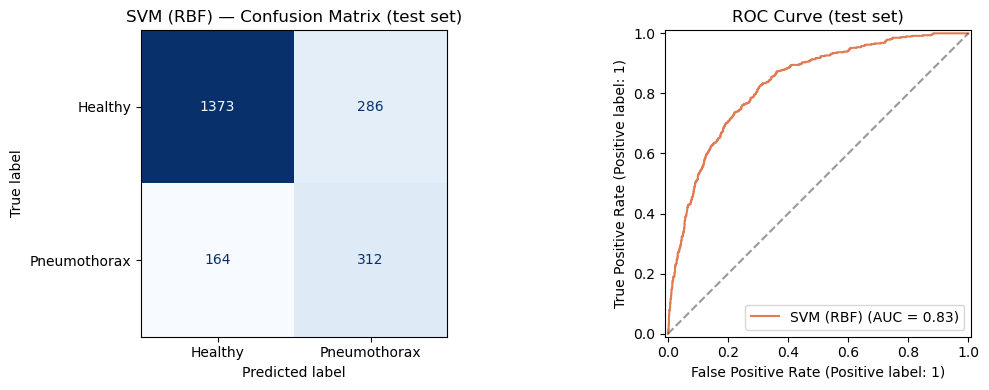

In [18]:
# Full evaluation of best model on a held-out test set
best_model_A_name = model_names[int(np.argmax(auc_means))]
best_model_A      = models[best_model_A_name]

print(f'Best model: {best_model_A_name}')

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_pneu, test_size=TEST_SIZE,
    stratify=y_pneu, random_state=RANDOM_STATE
)

best_model_A.fit(X_train, y_train)
y_pred_A = best_model_A.predict(X_test)
y_prob_A = best_model_A.predict_proba(X_test)[:, 1] if hasattr(best_model_A, 'predict_proba') \
           else best_model_A.decision_function(X_test)

print('\n── Classification Report (test set) ──')
print(classification_report(y_test, y_pred_A, target_names=['Healthy','Pneumothorax']))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred_A),
    display_labels=['Healthy','Pneumothorax']
).plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title(f'{best_model_A_name} — Confusion Matrix (test set)')

RocCurveDisplay.from_predictions(
    y_test, y_prob_A, ax=axes[1],
    name=best_model_A_name, color='#e07b54'
)
axes[1].plot([0,1],[0,1],'k--', alpha=0.4)
axes[1].set_title('ROC Curve (test set)')

plt.tight_layout()
plt.savefig('task_A_best_model.png', dpi=150, bbox_inches='tight')
plt.show()

### 7.4 Task B — Sex Prediction from X-ray

In [19]:
# Filter to patients with known sex
X_sex = X_all[sex_mask]
y_sex_clean = y_sex[sex_mask]

print('=== TASK B: Sex Prediction ===')
print(f'Classes: 0=Male ({(y_sex_clean==0).sum()}), 1=Female ({(y_sex_clean==1).sum()})\n')

# Rebuild model zoo with new class balance for sex
n_neg_sex = (y_sex_clean == 0).sum()
n_pos_sex = (y_sex_clean == 1).sum()

models_B = {
    'Logistic Regression': make_pipeline(
        LogisticRegression(max_iter=1000, class_weight='balanced',
                           random_state=RANDOM_STATE)
    ),
    'SVM (RBF)': make_pipeline(
        SVC(kernel='rbf', class_weight='balanced', probability=True,
            random_state=RANDOM_STATE)
    ),
    'Random Forest': make_pipeline(
        RandomForestClassifier(n_estimators=200, class_weight='balanced',
                               random_state=RANDOM_STATE, n_jobs=-1)
    ),
    'k-NN': make_pipeline(
        KNeighborsClassifier(n_neighbors=7, weights='distance', n_jobs=-1)
    ),
}
if HAS_XGB:
    models_B['XGBoost'] = make_pipeline(
        XGBClassifier(n_estimators=200, learning_rate=0.05,
                      scale_pos_weight=n_neg_sex / max(n_pos_sex, 1),
                      random_state=RANDOM_STATE, use_label_encoder=False,
                      eval_metric='logloss', n_jobs=-1)
    )

results_B = []
for name, pipe in models_B.items():
    print(f'  Training {name}...', end=' ')
    res = evaluate_cv(pipe, X_sex, y_sex_clean, label=name)
    results_B.append(res)
    print(f"AUC={res['AUC']}  F1={res['F1 (macro)']}")

summary_B = pd.DataFrame(results_B).set_index('Model')
summary_B_display = summary_B.drop(columns=['_auc_raw'])
print('\n── Task B Results ──')
print(summary_B_display.to_string())

=== TASK B: Sex Prediction ===
Classes: 0=Male (5880), 1=Female (4795)

  Training Logistic Regression... AUC=0.927 ± 0.006  F1=0.852 ± 0.006
  Training SVM (RBF)... AUC=0.964 ± 0.004  F1=0.896 ± 0.006
  Training Random Forest... AUC=0.890 ± 0.008  F1=0.761 ± 0.010
  Training k-NN... AUC=0.910 ± 0.004  F1=0.814 ± 0.005
  Training XGBoost... AUC=0.914 ± 0.007  F1=0.831 ± 0.006

── Task B Results ──
                               AUC     F1 (macro)       Accuracy    Sensitivity    Specificity
Model                                                                                         
Logistic Regression  0.927 ± 0.006  0.852 ± 0.006  0.853 ± 0.006  0.847 ± 0.006  0.858 ± 0.011
SVM (RBF)            0.964 ± 0.004  0.896 ± 0.006  0.897 ± 0.005  0.894 ± 0.009  0.899 ± 0.006
Random Forest        0.890 ± 0.008  0.761 ± 0.010  0.775 ± 0.009  0.589 ± 0.015  0.927 ± 0.009
k-NN                 0.910 ± 0.004  0.814 ± 0.005  0.820 ± 0.004  0.704 ± 0.012  0.915 ± 0.005
XGBoost              0.914 ± 

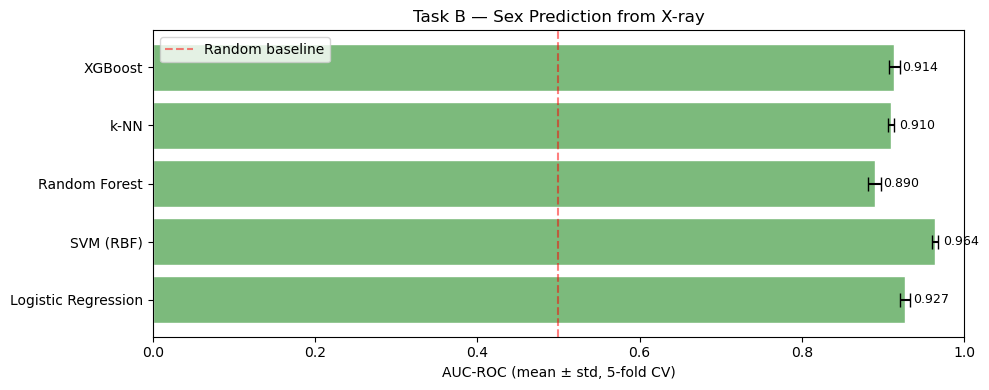

In [20]:
model_names_B = [r['Model'] for r in results_B]
auc_means_B   = [float(r['AUC'].split(' ± ')[0]) for r in results_B]
auc_stds_B    = [float(r['AUC'].split(' ± ')[1]) for r in results_B]

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(model_names_B, auc_means_B, xerr=auc_stds_B,
               color='#7cba7c', edgecolor='white', capsize=5)
ax.set_xlabel('AUC-ROC (mean ± std, 5-fold CV)')
ax.set_title('Task B — Sex Prediction from X-ray')
ax.axvline(0.5, color='red', linestyle='--', alpha=0.5, label='Random baseline')
ax.legend()
ax.set_xlim(0, 1)
for bar, val in zip(bars, auc_means_B):
    ax.text(val + 0.01, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('task_B_auc.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Robustness Checks

Per course requirements, we verify the stability and validity of our models.

In [21]:
### 7.5 Task C — Age Prediction from X-ray (Regression)

## Predicting patient age from chest X-ray images using regression models.

In [22]:
# Filter to patients with known age
age_mask = myDB_valid['Age'].notna()
X_age = X_all[age_mask]
y_age = myDB_valid.loc[age_mask, 'Age'].values

print('=== TASK C: Age Prediction (Regression) ===')
print(f'Patients with age data: {len(y_age)}')
print(f'Age range: {y_age.min():.0f} - {y_age.max():.0f} years')
print(f'Mean age: {y_age.mean():.1f} ± {y_age.std():.1f} years\n')

# Regression evaluation function
def evaluate_cv_regression(model, X, y, n_folds=N_FOLDS, label=''):
    from sklearn.model_selection import KFold
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
    
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=RANDOM_STATE)
    
    maes, rmses, r2s = [], [], []
    
    for train_idx, val_idx in kf.split(X):
        X_tr, X_val = X[train_idx], X[val_idx]
        y_tr, y_val = y[train_idx], y[val_idx]
        
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        
        maes.append(mean_absolute_error(y_val, y_pred))
        rmses.append(np.sqrt(mean_squared_error(y_val, y_pred)))
        r2s.append(r2_score(y_val, y_pred))
    
    results = {
        'Model' : label,
        'MAE'   : f'{np.mean(maes):.2f} ± {np.std(maes):.2f}',
        'RMSE'  : f'{np.mean(rmses):.2f} ± {np.std(rmses):.2f}',
        'R²'    : f'{np.mean(r2s):.3f} ± {np.std(r2s):.3f}',
    }
    return results

# Build regression models
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

def make_pipeline_reg(reg):
    return Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=PCA_VAR, random_state=RANDOM_STATE)),
        ('reg', reg)
    ])

models_C = {
    'Ridge': make_pipeline_reg(Ridge(alpha=1.0, random_state=RANDOM_STATE)),
    'Lasso': make_pipeline_reg(Lasso(alpha=0.1, random_state=RANDOM_STATE, max_iter=2000)),
    'Random Forest': make_pipeline_reg(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
    'SVR (RBF)': make_pipeline_reg(SVR(kernel='rbf', C=1.0)),
    'k-NN': make_pipeline_reg(KNeighborsRegressor(n_neighbors=7, weights='distance', n_jobs=-1)),
}

results_C = []
for name, pipe in models_C.items():
    print(f'  Training {name}...', end=' ')
    res = evaluate_cv_regression(pipe, X_age, y_age, label=name)
    results_C.append(res)
    print(f"MAE={res['MAE']}  R²={res['R²']}")

summary_C = pd.DataFrame(results_C).set_index('Model')
print('\n── Task C Results (Age Prediction) ──')
print(summary_C.to_string())

=== TASK C: Age Prediction (Regression) ===
Patients with age data: 10675
Age range: 1 - 413 years
Mean age: 47.1 ± 17.1 years

  Training Ridge... MAE=10.49 ± 0.24  R²=0.365 ± 0.031
  Training Lasso... MAE=10.43 ± 0.25  R²=0.375 ± 0.034
  Training Random Forest... MAE=11.99 ± 0.30  R²=0.228 ± 0.016
  Training SVR (RBF)... MAE=11.12 ± 0.29  R²=0.308 ± 0.031
  Training k-NN... MAE=11.16 ± 0.16  R²=0.299 ± 0.030

── Task C Results (Age Prediction) ──
                        MAE          RMSE             R²
Model                                                   
Ridge          10.49 ± 0.24  13.64 ± 1.02  0.365 ± 0.031
Lasso          10.43 ± 0.25  13.52 ± 1.05  0.375 ± 0.034
Random Forest  11.99 ± 0.30  15.03 ± 0.88  0.228 ± 0.016
SVR (RBF)      11.12 ± 0.29  14.23 ± 1.06  0.308 ± 0.031
k-NN           11.16 ± 0.16  14.31 ± 0.95  0.299 ± 0.030


Best model for Age Prediction: Lasso

── Age Prediction Results (test set) ──
MAE : 10.08 years
RMSE: 12.87 years
R²  : 0.384


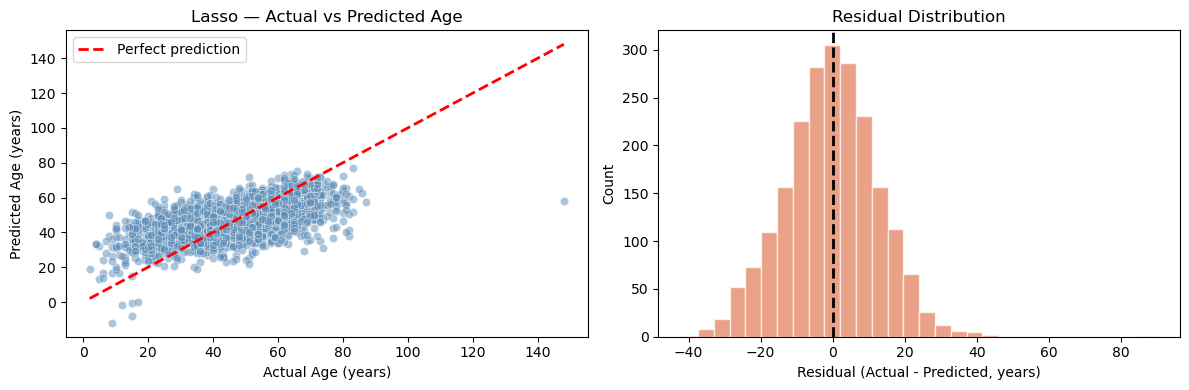

In [23]:
# Full evaluation of best model on held-out test set for Task C (Age Prediction)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

best_model_C_name = summary_C['MAE'].apply(lambda x: float(x.split(' ± ')[0])).idxmin()
best_model_C = models_C[best_model_C_name]

print(f'Best model for Age Prediction: {best_model_C_name}')

X_train_C, X_test_C, y_train_C, y_test_C = train_test_split(
    X_age, y_age, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

best_model_C.fit(X_train_C, y_train_C)
y_pred_C = best_model_C.predict(X_test_C)

mae_C = mean_absolute_error(y_test_C, y_pred_C)
rmse_C = np.sqrt(mean_squared_error(y_test_C, y_pred_C))
r2_C = r2_score(y_test_C, y_pred_C)

print(f'\n── Age Prediction Results (test set) ──')
print(f'MAE : {mae_C:.2f} years')
print(f'RMSE: {rmse_C:.2f} years')
print(f'R²  : {r2_C:.3f}')

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Scatter plot: predicted vs actual
axes[0].scatter(y_test_C, y_pred_C, alpha=0.5, color='#5b8db8', edgecolors='white', linewidth=0.5)
axes[0].plot([y_test_C.min(), y_test_C.max()], [y_test_C.min(), y_test_C.max()], 
             'r--', lw=2, label='Perfect prediction')
axes[0].set_xlabel('Actual Age (years)')
axes[0].set_ylabel('Predicted Age (years)')
axes[0].set_title(f'{best_model_C_name} — Actual vs Predicted Age')
axes[0].legend()

# Residual distribution
residuals = y_test_C - y_pred_C
axes[1].hist(residuals, bins=30, color='#e07b54', edgecolor='white', alpha=0.7)
axes[1].axvline(0, color='black', linestyle='--', linewidth=2)
axes[1].set_xlabel('Residual (Actual - Predicted, years)')
axes[1].set_ylabel('Count')
axes[1].set_title('Residual Distribution')

plt.tight_layout()
plt.savefig('task_C_best_model.png', dpi=150, bbox_inches='tight')
plt.show()

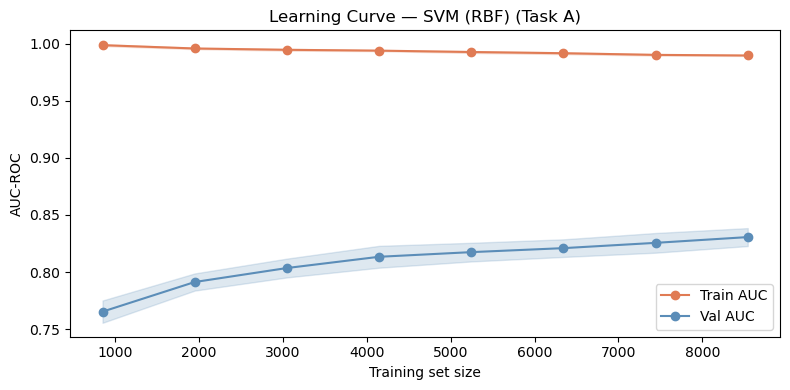

In [24]:
# ── 8.1 Learning curves: does performance saturate or still improve with more data? ──
from sklearn.model_selection import learning_curve

best_model_A.steps[-1][1].set_params()  # no-op, just ensure fitted

train_sizes, train_scores, val_scores = learning_curve(
    best_model_A, X_all, y_pneu,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring='roc_auc',
    train_sizes=np.linspace(0.1, 1.0, 8),
    n_jobs=-1
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(train_sizes, train_scores.mean(axis=1), 'o-', label='Train AUC',  color='#e07b54')
ax.fill_between(train_sizes,
                train_scores.mean(axis=1) - train_scores.std(axis=1),
                train_scores.mean(axis=1) + train_scores.std(axis=1),
                alpha=0.2, color='#e07b54')
ax.plot(train_sizes, val_scores.mean(axis=1),   'o-', label='Val AUC',    color='#5b8db8')
ax.fill_between(train_sizes,
                val_scores.mean(axis=1) - val_scores.std(axis=1),
                val_scores.mean(axis=1) + val_scores.std(axis=1),
                alpha=0.2, color='#5b8db8')
ax.set_xlabel('Training set size')
ax.set_ylabel('AUC-ROC')
ax.set_title(f'Learning Curve — {best_model_A_name} (Task A)')
ax.legend()
plt.tight_layout()
plt.savefig('learning_curve.png', dpi=150, bbox_inches='tight')
plt.show()

Permutation test:   0%|          | 0/100 [00:00<?, ?it/s]

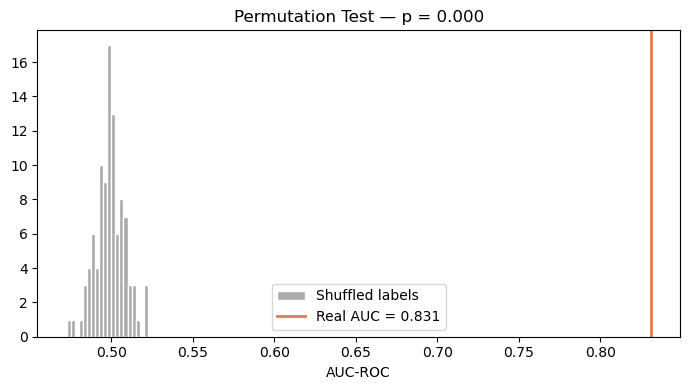

Real AUC : 0.8310
Permuted : 0.4989 ± 0.0090
p-value  : 0.0000  → SIGNIFICANT (p<0.05)


In [25]:
# ── 8.2 Permutation test — is the model better than chance? ──────────────────
# We shuffle labels 100 times and compare against the real AUC.
# If real AUC > 95th percentile of shuffled AUCs → p < 0.05

from sklearn.model_selection import cross_val_score

N_PERM = 100
perm_aucs = []

for _ in tqdm(range(N_PERM), desc='Permutation test'):
    y_shuffled = y_pneu.copy()
    np.random.shuffle(y_shuffled)
    scores = cross_val_score(
        best_model_A, X_all, y_shuffled,
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
        scoring='roc_auc', n_jobs=-1
    )
    perm_aucs.append(scores.mean())

real_auc = max(auc_means)  # best model AUC
p_value  = (np.array(perm_aucs) >= real_auc).mean()

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(perm_aucs, bins=20, color='#aaaaaa', edgecolor='white', label='Shuffled labels')
ax.axvline(real_auc, color='#e07b54', lw=2, label=f'Real AUC = {real_auc:.3f}')
ax.set_xlabel('AUC-ROC')
ax.set_title(f'Permutation Test — p = {p_value:.3f}')
ax.legend()
plt.tight_layout()
plt.savefig('permutation_test.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Real AUC : {real_auc:.4f}')
print(f'Permuted : {np.mean(perm_aucs):.4f} ± {np.std(perm_aucs):.4f}')
print(f'p-value  : {p_value:.4f}  {"→ SIGNIFICANT (p<0.05)" if p_value < 0.05 else "→ not significant"}')

In [26]:
# ── 8.3 Effect of CLAHE pre-processing ───────────────────────────────────────
# Compare the best model with and without CLAHE to justify preprocessing choice.

print('Checking impact of CLAHE...')

# Re-extract features WITHOUT CLAHE for comparison
X_no_clahe_list = []
for _, row in tqdm(myDB_valid.iterrows(), total=len(myDB_valid), desc='No-CLAHE features'):
    img_id = row['ImageId']
    if img_id not in dicom_map:
        continue
    try:
        img  = load_and_preprocess(dicom_map[img_id], clahe=False)
        feat = extract_all_features(img)
        X_no_clahe_list.append(feat)
    except:
        pass

# Make sure lengths match (re-use y_pneu from above)
n = min(len(X_no_clahe_list), len(y_pneu))
X_nc = np.array(X_no_clahe_list[:n], dtype=np.float32)
y_nc = y_pneu[:n]

import importlib
from sklearn.linear_model import LogisticRegression as LR
lr_pipe = make_pipeline(LR(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE))

res_clahe    = evaluate_cv(make_pipeline(LR(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)), X_all[:n], y_nc, label='With CLAHE')
res_no_clahe = evaluate_cv(make_pipeline(LR(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)), X_nc,      y_nc, label='Without CLAHE')

print(f"With CLAHE    AUC = {res_clahe['AUC']}")
print(f"Without CLAHE AUC = {res_no_clahe['AUC']}")

Checking impact of CLAHE...


No-CLAHE features:   0%|          | 0/10675 [00:00<?, ?it/s]

With CLAHE    AUC = 0.775 ± 0.009
Without CLAHE AUC = 0.774 ± 0.007


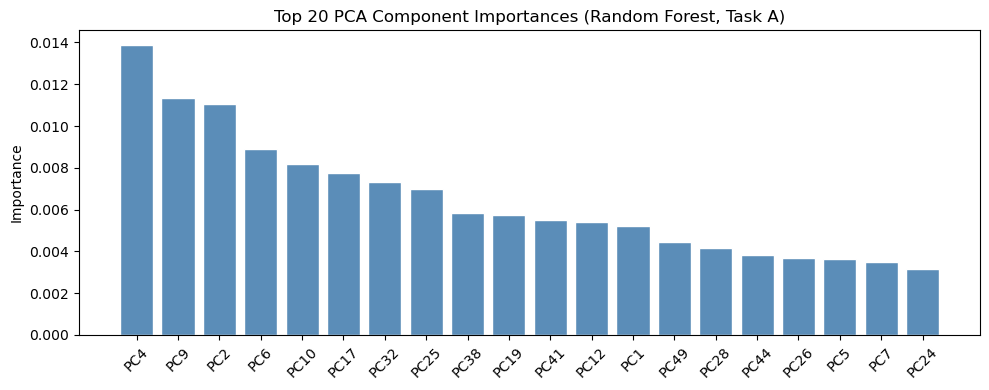

In [27]:
# ── 8.4 Feature importance (Random Forest) ───────────────────────────────────
rf_pipe = make_pipeline(
    RandomForestClassifier(n_estimators=200, class_weight='balanced',
                           random_state=RANDOM_STATE, n_jobs=-1)
)
rf_pipe.fit(X_all, y_pneu)

# PCA transforms the features, so we look at component-level importances
pca       = rf_pipe.named_steps['pca']
rf        = rf_pipe.named_steps['clf']
imp       = rf.feature_importances_
top_k     = 20
top_idx   = np.argsort(imp)[::-1][:top_k]

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(top_k), imp[top_idx], color='#5b8db8', edgecolor='white')
ax.set_xticks(range(top_k))
ax.set_xticklabels([f'PC{i+1}' for i in top_idx], rotation=45)
ax.set_title('Top 20 PCA Component Importances (Random Forest, Task A)')
ax.set_ylabel('Importance')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. SMOTE — Handling Class Imbalance

The dataset has ~75% healthy / ~25% pneumothorax patients. We already used `class_weight='balanced'` above. Here we additionally try SMOTE (Synthetic Minority Oversampling Technique) as an alternative strategy.

In [32]:
if HAS_SMOTE:
    from imblearn.pipeline import Pipeline as ImbPipeline
    
    smote_rf = ImbPipeline([
        ('scaler', StandardScaler()),
        ('pca',    PCA(n_components=PCA_VAR, random_state=RANDOM_STATE)),
        ('smote',  SMOTE(random_state=RANDOM_STATE)),
        ('clf',    RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))
    ])
    
    res_smote = evaluate_cv(smote_rf, X_all, y_pneu, label='RF + SMOTE')
    res_bw    = evaluate_cv(models['Random Forest'], X_all, y_pneu, label='RF + class_weight')
    
    print('Imbalance handling comparison (Task A, Random Forest):')
    print(f"  class_weight='balanced'  AUC = {res_bw['AUC']}")
    print(f"  SMOTE oversampling       AUC = {res_smote['AUC']}")
else:
    print('SMOTE not available — skipping this cell')

Imbalance handling comparison (Task A, Random Forest):
  class_weight='balanced'  AUC = 0.738 ± 0.013
  SMOTE oversampling       AUC = 0.719 ± 0.011


## 10. Final Summary

In [33]:
## 11. Gender Prediction Function

## Reusable function to predict gender from a new X-ray DICOM file.

def predict_gender(dcm_path, model=None):
    """
    Predict gender from a DICOM X-ray image.
    
    Parameters:
        dcm_path : str
            Path to the DICOM file
        model : sklearn Pipeline, optional
            Trained model for gender prediction. If None, uses best_model_B.
    
    Returns:
        dict with keys:
            - 'gender': 'Male' or 'Female'
            - 'probability': probability of being Female (class 1)
            - 'confidence': max(probability, 1-probability)
    """
    if model is None:
        model = best_model_B
    
    # Load and preprocess image
    img = load_and_preprocess(dcm_path)
    
    # Extract features
    features = extract_all_features(img).reshape(1, -1)
    
    # Predict
    pred = model.predict(features)[0]
    prob = model.predict_proba(features)[0, 1] if hasattr(model, 'predict_proba') else None
    
    gender = 'Female' if pred == 1 else 'Male'
    confidence = max(prob, 1 - prob) if prob is not None else None
    
    return {
        'gender': gender,
        'probability': prob,
        'confidence': confidence
    }

# Example usage:
# result = predict_gender('path/to/xray.dcm')
# print(f"Predicted gender: {result['gender']} (confidence: {result['confidence']:.2%})")


print("predict_gender() function defined. Use it to predict gender from new X-ray images.")

predict_gender() function defined. Use it to predict gender from new X-ray images.


In [34]:
## 12. Age Prediction Function

## Reusable function to predict age from a new X-ray DICOM file.

def predict_age(dcm_path, model=None):
    """
    Predict age from a DICOM X-ray image.
    
    Parameters:
        dcm_path : str
            Path to the DICOM file
        model : sklearn Pipeline, optional
            Trained regression model for age prediction. If None, uses best_model_C.
    
    Returns:
        dict with keys:
            - 'age': predicted age in years (float)
            - 'rounded': predicted age rounded to nearest integer
    """
    if model is None:
        model = best_model_C
    
    # Load and preprocess image
    img = load_and_preprocess(dcm_path)
    
    # Extract features
    features = extract_all_features(img).reshape(1, -1)
    
    # Predict
    pred = model.predict(features)[0]
    
    return {
        'age': pred,
        'rounded': round(pred)
    }

# Example usage:
# result = predict_age('path/to/xray.dcm')
# print(f"Predicted age: {result['rounded']} years (raw: {result['age']:.1f})")


print("predict_age() function defined. Use it to predict age from new X-ray images.")

predict_age() function defined. Use it to predict age from new X-ray images.


In [35]:
print('='*60)
print('  FINAL RESULTS SUMMARY')
print('='*60)
print('\n── Task A: Pneumothorax Classification ──')
print(summary_A_display.to_string())
print(f'\n  → Best model: {best_model_A_name}  (AUC {max(auc_means):.3f})')

print('\n── Task B: Sex Prediction ──')
print(summary_B_display.to_string())
best_B = model_names_B[int(np.argmax(auc_means_B))]
print(f'\n  → Best model: {best_B}  (AUC {max(auc_means_B):.3f})')

print('\n── Task C: Age Prediction ──')
print(summary_C.to_string())
best_C_mae = summary_C['MAE'].apply(lambda x: float(x.split(' ± ')[0])).min()
best_C = summary_C['MAE'].apply(lambda x: float(x.split(' ± ')[0])).idxmin()
print(f'\n  → Best model: {best_C}  (MAE {best_C_mae:.2f} years)')

print('\n── Key Design Choices ──')
choices = [
    ('Preprocessing',  'Resize to 128×128 + CLAHE normalisation'),
    ('Features',       'Global stats + HOG (edges) + LBP (texture) + quadrant asymmetry'),
    ('Dim. reduction', f'PCA retaining {int(PCA_VAR*100)}% variance (reduces noise, speeds up SVM/kNN)'),
    ('Imbalance',      "class_weight='balanced' (+ SMOTE if available)"),
    ('Evaluation',     f'Stratified {N_FOLDS}-fold CV → AUC, F1, Sensitivity, Specificity'),
    ('Robustness',     'Learning curves + permutation test for significance'),
]
for k, v in choices:
    print(f'  {k:20s}: {v}')

  FINAL RESULTS SUMMARY

── Task A: Pneumothorax Classification ──
                               AUC     F1 (macro)       Accuracy    Sensitivity    Specificity
Model                                                                                         
Logistic Regression  0.775 ± 0.009  0.658 ± 0.009  0.716 ± 0.010  0.685 ± 0.014  0.724 ± 0.014
SVM (RBF)            0.831 ± 0.008  0.723 ± 0.006  0.790 ± 0.005  0.671 ± 0.010  0.824 ± 0.006
Random Forest        0.738 ± 0.013  0.438 ± 0.001  0.777 ± 0.000  0.001 ± 0.001  1.000 ± 0.000
k-NN                 0.775 ± 0.009  0.643 ± 0.016  0.797 ± 0.007  0.316 ± 0.025  0.934 ± 0.004
XGBoost              0.775 ± 0.008  0.669 ± 0.007  0.789 ± 0.006  0.420 ± 0.015  0.895 ± 0.008

  → Best model: SVM (RBF)  (AUC 0.831)

── Task B: Sex Prediction ──
                               AUC     F1 (macro)       Accuracy    Sensitivity    Specificity
Model                                                                                         
Logistic